# 05 Sentiment Model Train & Apply

In [ ]:
!pip install pyarrow

## Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import re
import ast
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", 200)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATA_DIR = Path("/content/drive/MyDrive/NLP_Final_Project")

## Load and merge data

In [ ]:
df_clean = pd.read_parquet(DATA_DIR / "clean_news_final_project.parquet")
df_topics = pd.read_parquet(DATA_DIR / "doc_topics.parquet")
df_entities = pd.read_parquet(DATA_DIR / "doc_entities.parquet")

merge_keys = ["date", "domain", "title"]

clean_keep = [
    "date", "domain", "title", "url", "language",
    "text_clean", "clean_len", "has_residual_boilerplate"
]

topic_keep = [
    "date", "domain", "title",
    "topic_id", "topic_label", "industry", "topic_keep", "macro_topic"
]

entity_keep = [
    "date", "domain", "title",
    "org_list", "tech_list"
]

df_docs = (
    df_clean[clean_keep]
    .merge(df_topics[topic_keep], on=merge_keys, how="left")
    .merge(df_entities[entity_keep], on=merge_keys, how="left")
    .copy()
)

print(df_docs.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files exist:
clean_news_final_project.parquet: True
doc_topics.parquet: True
doc_entities.parquet: True
org_dict.csv: True
tech_dict.csv: True


## Sentence Segmentation

To train the sentiment classifier, we convert the article-level dataset into a sentence-level dataset.

Sentence-level analysis is preferred because a single article may contain both positive and negative statements about AI.  
By splitting articles into sentences, we can capture more precise sentiment signals and later aggregate them at the document, topic, or entity level.

### Sentence-level dataset

In [ ]:
def split_sentences(text):
    if pd.isna(text):
        return []
    text = str(text).strip()
    if text == "":
        return []
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()]

In [ ]:
df_docs["sentences"] = df_docs["text_clean"].apply(split_sentences)

df_sent = (
    df_docs.explode("sentences")
    .rename(columns={"sentences": "sentence"})
    .reset_index(drop=True)
)


Sentence dataset shape: (2510523, 16)


,date,domain,title,url,language,text_clean,clean_len,has_residual_boilerplate,topic_id,topic_label,industry,topic_keep,macro_topic,org_list,tech_list,sentence
0,2024-07-01,boingboing.net,This AI video of gymnastics might be the freak...,https://boingboing.net/2024/07/01/this-ai-vide...,en,This AI video of gymnastics might be the freak...,2615,False,6,Generative AI Applications,Software / AI Platforms,1,AI Applications,"[Apple, Yanartas, Microsoft]",[],This AI video of gymnastics might be the freak...
1,2024-07-01,boingboing.net,This AI video of gymnastics might be the freak...,https://boingboing.net/2024/07/01/this-ai-vide...,en,This AI video of gymnastics might be the freak...,2615,False,6,Generative AI Applications,Software / AI Platforms,1,AI Applications,"[Apple, Yanartas, Microsoft]",[],Whenever trying to get an Ai to communicate a ...
2,2024-07-01,boingboing.net,This AI video of gymnastics might be the freak...,https://boingboing.net/2024/07/01/this-ai-vide...,en,This AI video of gymnastics might be the freak...,2615,False,6,Generative AI Applications,Software / AI Platforms,1,AI Applications,"[Apple, Yanartas, Microsoft]",[],But then I see how they would render what's be...
3,2024-07-01,boingboing.net,This AI video of gymnastics might be the freak...,https://boingboing.net/2024/07/01/this-ai-vide...,en,This AI video of gymnastics might be the freak...,2615,False,6,Generative AI Applications,Software / AI Platforms,1,AI Applications,"[Apple, Yanartas, Microsoft]",[],Everything is just a flurry of limbs and rotat...
4,2024-07-01,boingboing.net,This AI video of gymnastics might be the freak...,https://boingboing.net/2024/07/01/this-ai-vide...,en,This AI video of gymnastics might be the freak...,2615,False,6,Generative AI Applications,Software / AI Platforms,1,AI Applications,"[Apple, Yanartas, Microsoft]",[],"On this wrestling AI video, Werners AI Art exp..."


In [ ]:
df_sent["sentence"] = (
    df_sent["sentence"]
    .fillna("")
    .astype(str)
    .str.replace("\n", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(df_sent.shape)

(2510523, 22)


### AI Sentence Filtering

The raw sentence dataset contains many sentences that are not directly related to AI impacts.

To improve annotation efficiency and model quality, we filter sentences that are more likely to describe AI-related developments.

#### Candidate filtering

In [ ]:
AI_KEYWORDS_STRICT = [
    "artificial intelligence",
    "machine learning",
    "deep learning",
    "generative ai",
    "genai",
    "large language model",
    "llm",
    "foundation model",
    "neural network",
    "chatgpt",
    "gpt-4",
    "gpt",
    "copilot",
    "automation",
    "autonomous system"
]

IMPACT_KEYWORDS = [
    "improve", "improved", "improves",
    "increase", "increased", "increases",
    "boost", "boosted", "boosts",
    "enhance", "enhanced", "enhances",
    "reduce", "reduced", "reduces",
    "save", "saves", "saving",
    "accelerate", "accelerated", "accelerates",
    "enable", "enabled", "enables",
    "transform", "transforms", "transformed",
    "benefit", "benefits",
    "productivity", "efficiency", "innovation",
    "risk", "risks",
    "harm", "harms", "harmful",
    "threat", "threaten", "threatens",
    "bias", "biased",
    "replace", "replaces", "replaced",
    "layoff", "layoffs",
    "privacy", "surveillance",
    "concern", "concerns",
    "misinformation",
    "regulation", "regulatory",
    "lawsuit", "unsafe",
    "uncertain", "uncertainty",
    "debate", "debated"
]

BOILERPLATE_PATTERNS = [
    r"read more",
    r"click here",
    r"subscribe",
    r"sign up",
    r"newsletter",
    r"advertisement",
    r"all rights reserved",
    r"copyright",
    r"thumbnail",
    r"video player",
]

PROMO_PATTERNS = [
    r"\$\d+",
    r"save \$",
    r"discount",
    r"deal",
    r"limited time",
    r"sale",
    r"coupon",
    r"lifetime license",
    r"upgrade now",
    r"buy now"
]

In [ ]:
def contains_any_keyword(text, keywords):
    if not isinstance(text, str) or text == "":
        return False
    text_low = text.lower()
    return any(k in text_low for k in keywords)

def contains_boilerplate(text):
    if not isinstance(text, str) or text == "":
        return False
    text_low = text.lower()
    return any(re.search(p, text_low) for p in BOILERPLATE_PATTERNS)

def contains_promo(text):
    if not isinstance(text, str) or text == "":
        return False
    text_low = text.lower()
    return any(re.search(p, text_low) for p in PROMO_PATTERNS)

In [ ]:
df_sent["sentence_len"] = df_sent["sentence"].str.len()
df_sent["word_count"] = df_sent["sentence"].str.split().str.len()

df_sent["has_ai_strict"] = df_sent["sentence"].apply(lambda x: contains_any_keyword(x, AI_KEYWORDS_STRICT))
df_sent["has_impact"] = df_sent["sentence"].apply(lambda x: contains_any_keyword(x, IMPACT_KEYWORDS))
df_sent["has_boilerplate_sent"] = df_sent["sentence"].apply(contains_boilerplate)
df_sent["has_promo"] = df_sent["sentence"].apply(contains_promo)

In [ ]:
df_sent_filtered = df_sent[
    (df_sent["sentence_len"] >= 40) &
    (df_sent["word_count"] >= 8) &
    (~df_sent["has_boilerplate_sent"]) &
    (~df_sent["has_promo"]) &
    (
        df_sent["has_ai_strict"] |
        df_sent["has_impact"]
    )
].copy()

print("Original sentences:", df_sent.shape)
print("Filtered sentences v2:", df_sent_filtered.shape)

Original sentences: (2510523, 22)
Filtered sentences v2: (596714, 22)


In [ ]:
df_sent_filtered.head()

,date,domain,title,url,language,text_clean,clean_len,has_residual_boilerplate,topic_id,topic_label,...,macro_topic,org_list,tech_list,sentence,sentence_len,word_count,has_ai_strict,has_impact,has_boilerplate_sent,has_promo
26,2024-09-22,boingboing.net,"If using AI feels like a chore, try this - Boi...",https://boingboing.net/2024/09/18/if-using-ai-...,en,"If using AI feels like a chore, try this - Boi...",3767,False,6,Generative AI Applications,...,AI Applications,"[Frenchie, Diskprices, Lenovo, Ebay, Stacksoci...","[Generative AI / LLM, AI Infrastructure / Chip...","If you want to make a blog post, you might sto...",232,48,True,False,False,False
28,2024-09-22,boingboing.net,"If using AI feels like a chore, try this - Boi...",https://boingboing.net/2024/09/18/if-using-ai-...,en,"If using AI feels like a chore, try this - Boi...",3767,False,6,Generative AI Applications,...,AI Applications,"[Frenchie, Diskprices, Lenovo, Ebay, Stacksoci...","[Generative AI / LLM, AI Infrastructure / Chip...","This AI hub puts AI models like GPT-4, GoogleA...",129,25,True,False,False,False
33,2024-09-22,boingboing.net,"If using AI feels like a chore, try this - Boi...",https://boingboing.net/2024/09/18/if-using-ai-...,en,"If using AI feels like a chore, try this - Boi...",3767,False,6,Generative AI Applications,...,AI Applications,"[Frenchie, Diskprices, Lenovo, Ebay, Stacksoci...","[Generative AI / LLM, AI Infrastructure / Chip...","It's got AI models like GPT-4, GoogleAI's Gemi...",197,32,True,False,False,False
36,2024-09-22,boingboing.net,"If using AI feels like a chore, try this - Boi...",https://boingboing.net/2024/09/18/if-using-ai-...,en,"If using AI feels like a chore, try this - Boi...",3767,False,6,Generative AI Applications,...,AI Applications,"[Frenchie, Diskprices, Lenovo, Ebay, Stacksoci...","[Generative AI / LLM, AI Infrastructure / Chip...",1minAI's got you covered with GPT-4 and Claude...,54,9,True,False,False,False
66,2024-03-13,clickup.com,Best AI Prompts for Business Risk Management,https://clickup.com/ai/prompts/business-risk-m...,en,Harness the power of ClickUp AI to make smarte...,2403,False,10,Enterprise AI Applications,...,AI Applications,[ClickUp],"[Cost Reduction / Efficiency, Governance / Com...",Harness the power of ClickUp AI to make smarte...,1272,165,False,True,False,False


After filtering, the remaining sentence pool is still too large for manual annotation.

To improve labeling efficiency, we assign each sentence a priority score based on whether it contains:

- AI-related keywords,
- impact-related keywords,
- organization mentions,
- technology mentions.

Higher-scoring sentences are more likely to provide informative sentiment examples.  
We then sample from different priority levels to create a balanced annotation set for manual labeling.

### Annotation sample construction

In [ ]:
def sentence_mentions_any(text, candidates):
    if not isinstance(text, str) or text == "":
        return False
    if not isinstance(candidates, list) or len(candidates) == 0:
        return False

    text_low = text.lower()
    for c in candidates:
        if isinstance(c, str):
            c = c.strip().lower()
            if c and c in text_low:
                return True
    return False

In [ ]:
df_sent_filtered["sent_has_org"] = df_sent_filtered.apply(
    lambda row: sentence_mentions_any(row["sentence"], row["org_list"]),
    axis=1
)

df_sent_filtered["sent_has_tech"] = df_sent_filtered.apply(
    lambda row: sentence_mentions_any(row["sentence"], row["tech_list"]),
    axis=1
)

#### Calculate pripority score

In [ ]:
df_sent_filtered["priority_score"] = (
    df_sent_filtered["has_ai_strict"].astype(int) * 2 +
    df_sent_filtered["has_impact"].astype(int) * 2 +
    df_sent_filtered["sent_has_org"].astype(int) * 1 +
    df_sent_filtered["sent_has_tech"].astype(int) * 1
)

df_sent_filtered["priority_score"].value_counts().sort_index()

,count
priority_score,
2,528873
4,67841


In [ ]:
df_annotation = (
    df_sent_filtered.query("priority_score >= 4")
    .sample(2000, random_state=42)
    .drop_duplicates(subset=["url", "sentence"])
    .reset_index(drop=True)
)

cols = [
    "date", "domain", "title", "url",
    "topic_label", "macro_topic", "org_list", "tech_list",
    "sentence", "priority_score"
]

df_annotation = df_annotation[cols].copy()
df_annotation["label"] = ""
df_annotation["notes"] = ""
df_annotation["annotator"] = ""

print(df_annotation.shape)

,sentence,topic_label,org_list,tech_list,priority_score
592486,The new funding will support the company’s eff...,Noise / Complaint Pages,[],"[Automation, Workflow Redesign, Governance / C...",4
791710,The only improvement I can suggest is to load ...,Generative AI Applications,"[Chevron, Divyansh, Learnerschevron]","[AI Services / Cloud, Data / Model Training]",4
310315,"""Synthesis AI was founded on the thesis that t...",Enterprise AI Applications,"[Cvml, Arvr, Synthesis, Vton]","[Generative AI / LLM, AI Services / Cloud]",4
1851710,Hong Kong is testing out its own ChatGPT-style...,AI Policy and Geopolitics,"[Microsoft, Houthi, Google, OpenAI, Sensetime,...","[Generative AI / LLM, AI Research / Development]",4
654378,POLY-ML is funded by the Valencian Institute o...,Enterprise AI Applications,"[Erdf, Polyml]","[Cost Reduction / Efficiency, Generative AI / ...",4
2121499,“ServiceNow does things differently – deliveri...,Enterprise AI Applications,"[Proassurance, ServiceNow, Customer, Moengage,...","[Automation, Workflow Redesign, Cost Reduction...",4
1762975,/RELATED PEOPLEPersonDemis HassabisIN THIS ART...,Generative AI Applications,"[Penberthy, Takeour, Engineeringthe]","[Generative AI / LLM, AI Research / Development]",4
348529,This enables developers to create innovative a...,Enterprise AI Applications,"[Mediatek, Cortexa, TSMC]","[Cost Reduction / Efficiency, Governance / Com...",4
972123,"As for the performance, This undetectable AI w...",Generative AI Applications,"[Writehuman, Google, Humbot, Turnitin, Keyword...","[Augmentation, Cost Reduction / Efficiency, Ro...",4
1665328,"Artificial intelligence, machine learning, mac...",Telecom and Consumer Technology,"[Micron, NVIDIA, AMD, Mediatek, Samsung, Googl...","[Automation, Augmentation, Cost Reduction / Ef...",4


### LLM-assisted labeling

API/LLM was used only for pre-labeling assistance, while the final sentiment classifier was trained separately on the labeled dataset.

In [ ]:
from openai import OpenAI
from tqdm import tqdm

client = OpenAI(api_key="YOUR_API_KEY")


def label_sentence(sentence):

    prompt = f"""
You are labeling AI impact sentiment.

Classify the sentence into one label:

positive
negative
uncertain_mixed

Return ONLY the label.

Sentence:
{sentence}
"""

    try:
        response = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[{"role": "user", "content": prompt}],
            temperature=0
        )

        label = response.choices[0].message.content.strip().lower()

        return label

    except Exception as e:
        return "error"

In [ ]:
labels = []

for sentence in tqdm(df_annotation["sentence"]):

    label = label_sentence(sentence)

    labels.append(label)

df_annotation["label"] = labels

100%|██████████| 2000/2000 [12:25<00:00,  2.68it/s]


#### Label quality check

In [ ]:
df_annotation["label"] = df_annotation["label"].str.strip().str.lower()

print(df_annotation["label"].value_counts())
print(set(df_annotation["label"]))

label
positive           1160
uncertain_mixed     525
negative            315
Name: count, dtype: int64
{'negative', 'uncertain_mixed', 'positive'}


In [ ]:
df_annotation[df_annotation["label"]=="positive"].sample(10)[["sentence"]]

,sentence
40,This integration elevates the features of Siri...
1966,The hightlight is the introduction of the Chat...
1168,ETCIO Online Tech Quizzing Festival Automation...
1029,Vous ne trouvez aucun robot qui vous convient ...
259,The effort goes beyond jumping on the artifici...
895,This automation reduces human error and saves ...
1623,"At its core, AI video production utilizes arti..."
1607,"Interestingly, it is already estimated to have..."
1869,"Furthermore, AI enables engagement with client..."
1399,(TSXV:CYBE) is a cybersecurity company that pr...


In [ ]:
df_annotation[df_annotation["label"]=="negative"].sample(10)[["sentence"]]

,sentence
757,They have also summoned billionaire owner Elon...
1754,Musk's xAI last month accused Li in a lawsuit ...
306,Electricity Prices Will Increase The inevitabl...
391,ChatGPT plugin flaws introduce enterprise secu...
958,"For businesses, this escalating potential for ..."
818,"U.S., drafting guidelines for use of artificia..."
534,Microsoft to delay release of Recall AI featur...
671,The New York City education department said on...
795,The lawsuit also cites a high-profile leadersh...
1612,Artificial Intelligence poses several potentia...


In [ ]:
df_annotation[df_annotation["label"]=="uncertain_mixed"].sample(10)[["sentence"]]

,sentence
1664,The late pope criticized both laissez-faire ca...
468,Deploying Generative AI in an Enterprise Setti...
1311,But it’s “not applicable” to foundation models...
367,Rosário told The Associated Press that he aske...
1916,Its stated aims were to “advance digital intel...
1593,But it’s “not applicable” to foundation models...
956,© 2024 KLCCKLCC136 W 8th AveEugene OR 97401541...
1430,"Artificial intelligence, automation and roboti..."
1300,While an parliamentarians disagree over the co...
439,"Biden says there is need to address security, ..."


In [ ]:
df_annotation = df_annotation[df_annotation["label"].isin(["positive", "negative", "uncertain_mixed"])].copy()

df_annotation.to_csv(DATA_DIR / "sent_annotation_labeled_2000.csv", index=False)
df_annotation.to_parquet(DATA_DIR / "sent_annotation_labeled_2000.parquet", index=False)

## Sentiment Model Training

After constructing and labeling the sentence-level dataset, we fine-tune a transformer-based classifier for AI Impact Sentiment.

The task is formulated as a 3-class sentence classification problem:

- positive
- negative
- uncertain_mixed

We use a pre-trained encoder and fine-tune it on our labeled news sentences.  
This satisfies the requirement that the sentiment model must be trained for the project rather than relying on an already fine-tuned sentiment classifier.

In [ ]:
df_labeled = pd.read_csv(DATA_DIR / "sent_annotation_labeled_2000.csv")

print("Loaded labeled dataset:", df_labeled.shape)
df_labeled.head(3)

Loaded labeled dataset: (2000, 13)


,date,domain,title,url,topic_label,macro_topic,org_list,tech_list,sentence,priority_score,label,notes,annotator
0,2025-06-26,www.einpresswire.com,Sciencia AI Secures Funding to Expand AI In...,https://www.einpresswire.com/article/825821915...,Noise / Complaint Pages,NaN,[],['Automation' 'Workflow Redesign' 'Governance ...,The new funding will support the company’s eff...,4,positive,NaN,NaN
1,2022-05-30,www.coursera.org,Learner Reviews & Feedback for Machine Learnin...,https://www.coursera.org/projects/azure-machin...,Generative AI Applications,AI Applications,['Chevron' 'Divyansh' 'Learnerschevron'],['AI Services / Cloud' 'Data / Model Training'],The only improvement I can suggest is to load ...,4,positive,NaN,NaN
2,2023-04-18,www.kcbd.com,"Synthesis AI Unveils Synthesis Labs, Showcasin...",https://www.kcbd.com/prnewswire/2023/04/18/syn...,Enterprise AI Applications,AI Applications,['Cvml' 'Arvr' 'Synthesis' 'Vton'],['Generative AI / LLM' 'AI Services / Cloud'],"""Synthesis AI was founded on the thesis that t...",4,positive,NaN,NaN


In [ ]:
df_labeled = df_annotation.copy()
df_labeled = df_labeled.drop(columns=["notes", "annotator"], errors="ignore")
df_labeled = df_labeled[["sentence", "label"]].copy()

print(df_labeled.shape)
df_labeled.head()

(2000, 2)


,sentence,label
0,The new funding will support the company’s eff...,positive
1,The only improvement I can suggest is to load ...,positive
2,"""Synthesis AI was founded on the thesis that t...",positive
3,Hong Kong is testing out its own ChatGPT-style...,uncertain_mixed
4,POLY-ML is funded by the Valencian Institute o...,positive


In [ ]:
label2id = {
    "negative": 0,
    "uncertain_mixed": 1,
    "positive": 2
}

id2label = {v: k for k, v in label2id.items()}

df_labeled["label_id"] = df_labeled["label"].map(label2id)

df_labeled.head()

,sentence,label,label_id
0,The new funding will support the company’s eff...,positive,2
1,The only improvement I can suggest is to load ...,positive,2
2,"""Synthesis AI was founded on the thesis that t...",positive,2
3,Hong Kong is testing out its own ChatGPT-style...,uncertain_mixed,1
4,POLY-ML is funded by the Valencian Institute o...,positive,2


### train / validation / test split

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_labeled,
    test_size=0.30,
    stratify=df_labeled["label_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("train:", train_df.shape)
print("val:", val_df.shape)
print("test:", test_df.shape)

train: (1400, 3)
val: (300, 3)
test: (300, 3)


In [ ]:
train_df.head()

,sentence,label,label_id
1384,With concerns over data flow and storage in Ch...,negative,0
1699,business can effectively plan strategies for e...,positive,2
1202,"Furthermore, increase in investment for artifi...",positive,2
1348,Malaysia Takes Legal Aim at Elon Musk's X Over...,negative,0
115,Sourcing effective solutions will ensure compa...,uncertain_mixed,1


## Transformer training

We fine-tuned roberta-base on our project-specific sentiment labels.

In [ ]:
!pip -q install transformers datasets accelerate evaluate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.3 MB/s eta 0:00:00


### Convert to Hugging Face dataset

In [ ]:
from datasets import Dataset

train_ds = Dataset.from_pandas(
    train_df[["sentence", "label_id"]].rename(columns={"label_id": "label"})
)

val_ds = Dataset.from_pandas(
    val_df[["sentence", "label_id"]].rename(columns={"label_id": "label"})
)

test_ds = Dataset.from_pandas(
    test_df[["sentence", "label_id"]].rename(columns={"label_id": "label"})
)


train_ds = train_ds.remove_columns(["__index_level_0__"])
val_ds = val_ds.remove_columns(["__index_level_0__"])
test_ds = test_ds.remove_columns(["__index_level_0__"])

print(train_ds)
print(val_ds)
print(test_ds)

Dataset({
    features: ['sentence', 'label'],
    num_rows: 1400
})
Dataset({
    features: ['sentence', 'label'],
    num_rows: 300
})
Dataset({
    features: ['sentence', 'label'],
    num_rows: 300
})


### Tokenizer

In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_ds = train_ds.map(tokenize_function, batched=True)
val_ds = val_ds.map(tokenize_function, batched=True)
test_ds = test_ds.map(tokenize_function, batched=True)

Map:   0%|          | 0/1400 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

### Label mapping

In [ ]:
label2id = {
    "negative": 0,
    "uncertain_mixed": 1,
    "positive": 2
}

id2label = {v: k for k, v in label2id.items()}

### Initialize Model

In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Metrics

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_f1": f1,
        "macro_precision": precision,
        "macro_recall": recall
    }

### Trainer setup

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir=str(DATA_DIR / "sentiment_model_roberta"),
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=20,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

train_ds.set_format("torch")
val_ds.set_format("torch")
test_ds.set_format("torch")

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.483747,0.520207,0.780000,0.718271,0.773620,0.716507
2,0.391340,0.536437,0.783333,0.707896,0.726415,0.722920
3,0.274234,0.468904,0.843333,0.799571,0.801632,0.797731


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=264, training_loss=0.45553585717623885, metrics={'train_runtime': 27.5489, 'train_samples_per_second': 152.456, 'train_steps_per_second': 9.583, 'total_flos': 276269088614400.0, 'train_loss': 0.45553585717623885, 'epoch': 3.0})

### Evaluate on test dataset

In [ ]:
test_metrics = trainer.evaluate(test_ds)
test_metrics

{'eval_loss': 0.4276762008666992,
 'eval_accuracy': 0.8233333333333334,
 'eval_macro_f1': 0.7636857157183442,
 'eval_macro_precision': 0.7616025660392559,
 'eval_macro_recall': 0.7700596816976127,
 'eval_runtime': 0.2465,
 'eval_samples_per_second': 1216.921,
 'eval_steps_per_second': 77.072,
 'epoch': 3.0}

### Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd
import numpy as np

test_pred = trainer.predict(test_ds)
y_true = test_pred.label_ids
y_pred = np.argmax(test_pred.predictions, axis=1)

cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=[id2label[i] for i in range(3)],
    columns=[id2label[i] for i in range(3)]
)

display(cm_df)

print(classification_report(
    y_true,
    y_pred,
    target_names=[id2label[i] for i in range(3)],
    digits=4,
    zero_division=0
))

,negative,uncertain_mixed,positive
negative,37,10,1
uncertain_mixed,18,47,13
positive,0,11,163


                 precision    recall  f1-score   support

       negative     0.6727    0.7708    0.7184        48
uncertain_mixed     0.6912    0.6026    0.6438        78
       positive     0.9209    0.9368    0.9288       174

       accuracy                         0.8233       300
      macro avg     0.7616    0.7701    0.7637       300
   weighted avg     0.8215    0.8233    0.8210       300



### Save Sentiment Model

In [ ]:
MODEL_SAVE_DIR = DATA_DIR / "roberta_ai_impact_sentiment"

trainer.save_model(str(MODEL_SAVE_DIR))
tokenizer.save_pretrained(str(MODEL_SAVE_DIR))

print("Saved model to:", MODEL_SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to: /content/drive/MyDrive/NLP_Final_Project/roberta_ai_impact_sentiment


## Apply the model to the full corpus

In [ ]:
df_apply = df_sent_filtered.copy()
print(df_apply.shape)

(596714, 25)


In [ ]:
df_apply.columns

Index(['date', 'domain', 'title', 'url', 'language', 'text_clean', 'clean_len',
       'has_residual_boilerplate', 'topic_id', 'topic_label', 'industry',
       'topic_keep', 'macro_topic', 'org_list', 'tech_list', 'sentence',
       'sentence_len', 'word_count', 'has_ai_strict', 'has_impact',
       'has_boilerplate_sent', 'has_promo', 'sent_has_org', 'sent_has_tech',
       'priority_score'],
      dtype='object')

### Convert the corpus to HuggingFace Dataset

In [ ]:
from datasets import Dataset

apply_ds = Dataset.from_pandas(df_apply[["sentence"]].copy())

apply_ds

Dataset({
    features: ['sentence', '__index_level_0__'],
    num_rows: 596714
})

### Tokenize the full dataset

In [ ]:
def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

apply_ds = apply_ds.map(tokenize_function, batched=True)

Map:   0%|          | 0/596714 [00:00<?, ? examples/s]

### Prepare dataset for model inference

In [ ]:
cols_to_remove = [c for c in ["sentence", "__index_level_0__"] if c in apply_ds.column_names]
if cols_to_remove:
    apply_ds = apply_ds.remove_columns(cols_to_remove)

apply_ds

Dataset({
    features: ['input_ids', 'attention_mask'],
    num_rows: 596714
})

### Generate sentiment predictions

In [ ]:
pred_output = trainer.predict(apply_ds)

### Convert logits to probabilities and predicted labels

In [ ]:
import numpy as np
from scipy.special import softmax

logits = pred_output.predictions
probs = softmax(logits, axis=1)

df_apply["prob_negative"] = probs[:, 0]
df_apply["prob_uncertain"] = probs[:, 1]
df_apply["prob_positive"] = probs[:, 2]

id2label = {0: "negative", 1: "uncertain_mixed", 2: "positive"}

df_apply["pred_id"] = np.argmax(probs, axis=1)
df_apply["pred_label"] = df_apply["pred_id"].map(id2label)

In [ ]:
df_apply["pred_label"].value_counts()

,count
pred_label,
positive,359836
uncertain_mixed,145717
negative,91161


## Sentence-level Result

In [ ]:
sent_sentence_cols = [
    "url", "date", "topic_label", "macro_topic",
    "org_list", "tech_list",
    "sentence",
    "prob_negative", "prob_uncertain", "prob_positive",
    "pred_label"
]

sent_sentence_cols = [c for c in sent_sentence_cols if c in df_apply.columns]

sent_sentence = df_apply[sent_sentence_cols].copy()
sent_sentence.to_parquet(DATA_DIR / "sent_sentence.parquet", index=False)

print(sent_sentence.shape)
print("Saved sent_sentence.parquet")

(596714, 11)
Saved sent_sentence.parquet


## Document-level aggregation

In [ ]:
doc_key = "url"

sent_doc = (
    df_apply.groupby(doc_key)
    .agg(
        date=("date", "first"),
        topic_label=("topic_label", "first"),
        macro_topic=("macro_topic", "first"),
        prob_negative=("prob_negative", "mean"),
        prob_uncertain=("prob_uncertain", "mean"),
        prob_positive=("prob_positive", "mean"),
        n_sentences=("sentence", "count")
    )
    .reset_index()
)

sent_doc["doc_pred"] = (
    sent_doc[["prob_negative", "prob_uncertain", "prob_positive"]]
    .idxmax(axis=1)
    .str.replace("prob_", "", regex=False)
)

sent_doc.to_parquet(DATA_DIR / "sent_doc.parquet", index=False)

print(sent_doc.shape)
print("Saved sent_doc.parquet")

(99770, 9)
Saved sent_doc.parquet


## Monthly

In [ ]:
import pandas as pd

df_apply["date"] = pd.to_datetime(df_apply["date"], errors="coerce")
df_apply["month"] = df_apply["date"].dt.to_period("M").astype(str)

df_apply[["date", "month"]].head()

,date,month
26,2024-09-22,2024-09
28,2024-09-22,2024-09
33,2024-09-22,2024-09
36,2024-09-22,2024-09
66,2024-03-13,2024-03


## Topic × Time aggregation


In [143]:
sent_topic_time = (
    df_apply.groupby(["month", "topic_label"])
    .agg(
        avg_negative=("prob_negative", "mean"),
        avg_uncertain=("prob_uncertain", "mean"),
        avg_positive=("prob_positive", "mean"),
        n_sentences=("sentence", "count")
    )
    .reset_index()
)

sent_topic_time.to_csv(DATA_DIR / "sent_topic_time.csv", index=False)

print(sent_topic_time.shape)
print("Saved sent_topic_time.csv")

(852, 6)
Saved sent_topic_time.csv


## Entity × Time aggregation

### Convert 'org_list' numpy array to list

In [144]:
df_entity = df_apply.copy()

df_entity["org_list"] = df_entity["org_list"].apply(
    lambda x: list(x) if isinstance(x, np.ndarray) else x
)

df_entity = df_entity.explode("org_list")

df_entity = df_entity[
    df_entity["org_list"].notna() &
    (df_entity["org_list"] != "")
].copy()

In [150]:
sent_entity_time = (
    df_entity.groupby(["month", "org_list"])
    .agg(
        avg_negative=("prob_negative", "mean"),
        avg_uncertain=("prob_uncertain", "mean"),
        avg_positive=("prob_positive", "mean"),
        n_sentences=("sentence", "count")
    )
    .reset_index()
    .rename(columns={"org_list": "entity"})
)

sent_entity_time.to_csv(DATA_DIR / "sent_entity_time.csv", index=False)
print("Saved sent_entity_time.csv")

Saved sent_entity_time.csv


## Visualization

### Top AI companies sentiment ranking

In [ ]:
entity_summary = (
    sent_entity_time
    .groupby("entity")
    .agg(
        avg_positive=("avg_positive","mean"),
        avg_negative=("avg_negative","mean"),
        mentions=("n_sentences","sum")
    )
    .reset_index()
)

entity_summary = entity_summary[entity_summary["mentions"] >= 50]

top_positive = entity_summary.sort_values(
    "avg_positive", ascending=False
).head(20)

top_positive

,entity,avg_positive,avg_negative,mentions
41413,Mwcs,0.991871,0.002664,50
64420,Uowd,0.991771,0.002775,96
644,Adib,0.991556,0.003168,128
19669,Ecolibriumecolibrium,0.991534,0.002289,86
31160,Integral,0.991476,0.002291,99
57237,Smartsense,0.991476,0.002291,99
19668,Ecolibrium,0.991476,0.002291,99
7163,Beratv,0.991403,0.003026,104
15381,Crestal,0.991403,0.003026,104
17036,Decimal,0.991403,0.003026,104


### Topic sentiment comparison

In [ ]:
topic_sentiment = (
    df_apply
    .groupby("topic_label")
    .agg(
        avg_positive=("prob_positive","mean"),
        avg_negative=("prob_negative","mean"),
        n_sentences=("sentence","count")
    )
    .reset_index()
)

topic_sentiment.sort_values("avg_positive", ascending=False)

,topic_label,avg_positive,avg_negative,n_sentences
1,AI Media Generation,0.974580,0.003722,1371
19,Telecom and Consumer Technology,0.892991,0.040627,15388
16,Noise / Complaint Pages,0.846944,0.059184,22116
7,Enterprise AI Applications,0.807951,0.059806,139280
13,Machine Learning and Data Science,0.731579,0.107197,47327
11,Healthcare AI,0.705434,0.109734,20414
18,Regional AI Market News,0.679405,0.085935,20450
14,Microsoft AI Ecosystem,0.671858,0.119314,12105
8,Finance / Stock Ticker Pages,0.654636,0.103336,2479
5,Corporate PR Statements,0.643429,0.158518,8071


### AI sentiment over time

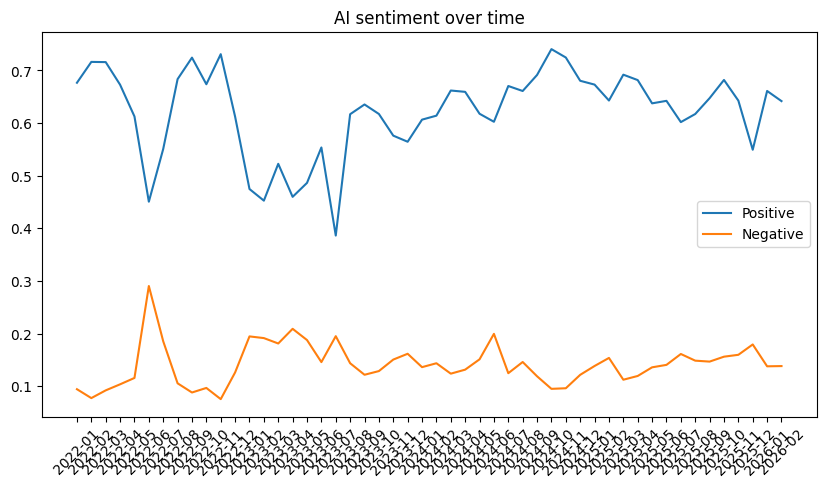

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# create month column
sent_sentence["month"] = pd.to_datetime(sent_sentence["date"]).dt.to_period("M")

# aggregate
monthly_sent = (
    sent_sentence
    .groupby("month")
    .agg(
        avg_positive=("prob_positive","mean"),
        avg_negative=("prob_negative","mean")
    )
    .reset_index()
)

monthly_sent = monthly_sent.sort_values("month")

# plot
plt.figure(figsize=(10,5))

plt.plot(monthly_sent["month"].astype(str), monthly_sent["avg_positive"], label="Positive")
plt.plot(monthly_sent["month"].astype(str), monthly_sent["avg_negative"], label="Negative")

plt.xticks(rotation=45)
plt.legend()
plt.title("AI sentiment over time")

plt.show()